## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [7]:
data = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df = data

In [8]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [10]:
cat = df.select_dtypes(exclude="number")
crosstab_1 = pd.crosstab(cat['category'], cat['isBestSeller'])
crosstab_1

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [ ]:
df["isBestSeller"].unique()


array([False,  True])

In [ ]:
prop = (df.groupby("category")["isBestSeller"]
    .apply(lambda x: (x == True).mean() * 100)
    .sort_values(ascending=False)
)

print("Percentage of best-sellers by category:\n")
print(prop.round(2).astype(str) + " %")



Percentage of best-sellers by category:

category
Grocery                           5.81 %
Smart Home Security & Lighting    5.77 %
Health & Personal Care            5.77 %
Mobile Phone Accessories          4.25 %
Power & Hand Tools                3.53 %
                                   ...  
Bedding Collections                0.0 %
CPUs                               0.0 %
CD, Disc & Tape Players            0.0 %
Blank Media Cases & Wallets        0.0 %
eBook Readers & Accessories        0.0 %
Name: isBestSeller, Length: 296, dtype: object


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [11]:
from scipy.stats import chi2_contingency

In [14]:
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_1)

In [ ]:
float(chi2_pvalue) < 0.05

#Because p = 0.00003 < 0.05, we reject the null hypothesis.
#That means → Best-seller distribution is not independent of product category
#Best-seller status depends on the category. Some categories have more best-sellers than others.

True

In [22]:
chi2, p, dof, expected = chi2_contingency(crosstab_1)

print(f"Chi-square: {chi2:.3f}")
print(f"p-value: {p:.4f}")
print(f"Degrees of freedom: {dof}")
print("Expected frequencies:\n", expected)

n = crosstab_1.sum().sum()
k = min(crosstab_1.shape)
cramers_v = np.sqrt(chi2 / (n * (k - 1)))

print(f"\nCramér's V: {cramers_v:.3f}")

Chi-square: 36540.203
p-value: 0.0000
Degrees of freedom: 295
Expected frequencies:
 [[2.47190130e+02 8.09870149e-01]
 [4.05371878e+03 1.32812173e+01]
 [2.49183599e+02 8.16401360e-01]
 [1.69145827e+03 5.54173243e+00]
 [2.53170536e+02 8.29463782e-01]
 [8.50214439e+03 2.78556144e+01]
 [1.06650580e+02 3.49419782e-01]
 [2.57157474e+02 8.42526204e-01]
 [9.51781673e+03 3.11832664e+01]
 [1.50008526e+04 4.91473619e+01]
 [9.32544700e+03 3.05530045e+01]
 [2.38219520e+02 7.80479700e-01]
 [3.22941944e+03 1.05805616e+01]
 [9.44704859e+03 3.09514084e+01]
 [6.68808779e+03 2.19122125e+01]
 [5.26275760e+02 1.72423967e+00]
 [1.90296531e+04 6.23469391e+01]
 [2.77191835e+03 9.08164873e+00]
 [2.53170536e+02 8.29463782e-01]
 [4.04674164e+02 1.32583581e+00]
 [1.92489346e+04 6.30653723e+01]
 [3.10482764e+03 1.01723609e+01]
 [2.04330551e+02 6.69449115e-01]
 [6.28839730e+03 2.06027047e+01]
 [5.23385231e+03 1.71476942e+01]
 [9.52180367e+03 3.11963288e+01]
 [2.48186864e+02 8.13135755e-01]
 [9.46598655e+03 3.10134

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

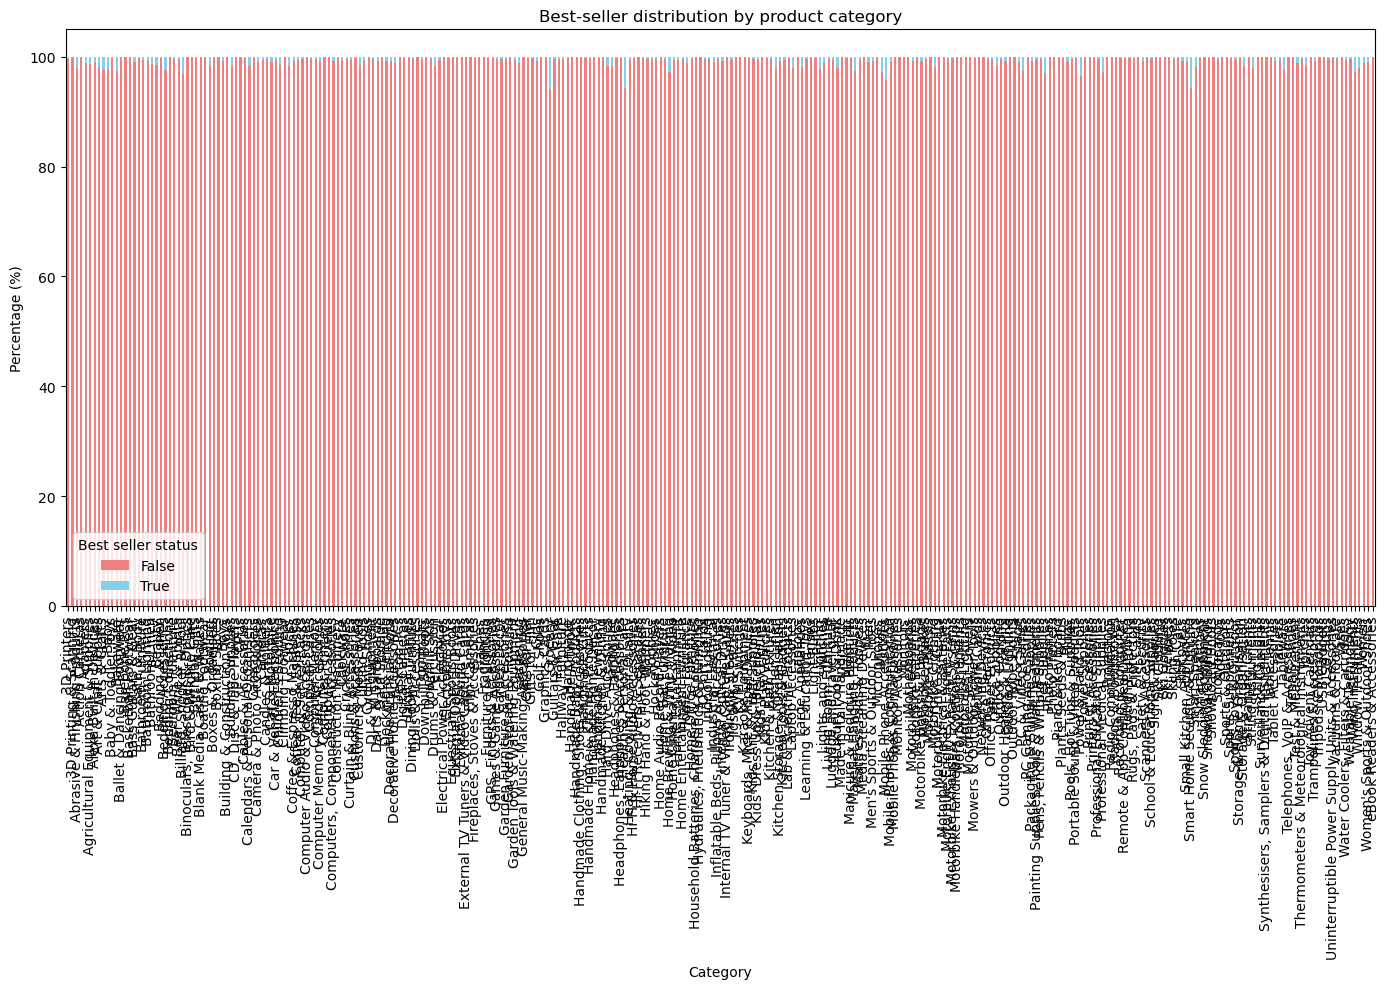

In [ ]:
crosstab_percent = crosstab_1.div(crosstab_1.sum(axis=1), axis=0) * 100

crosstab_percent.plot(kind="bar", stacked=True, figsize=(14,10), color=["lightcoral", "skyblue"])

plt.title("Best-seller distribution by product category")
plt.xlabel("Category")
plt.ylabel("Percentage (%)")
plt.legend(title="Best seller status")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [37]:

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Original dataset: {len(df)} rows")
print(f"After removing outliers: {len(df_no_outliers)} rows")
print(f"Outliers removed: {len(df) - len(df_no_outliers)}")


Original dataset: 2443651 rows
After removing outliers: 2115963 rows
Outliers removed: 327688


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.


C:\Users\diogo\AppData\Local\Temp\ipykernel_27280\1679964306.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', palette='Set1')


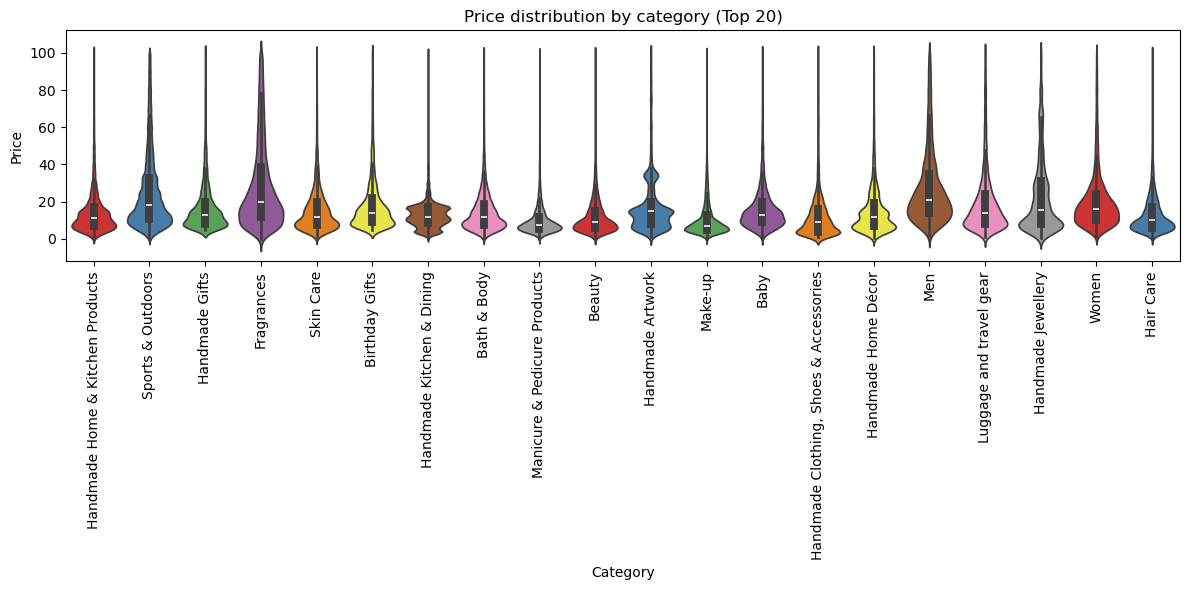

In [ ]:
top20 = df_no_outliers["category"].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers["category"].isin(top20)]

#create the violin plot
plt.figure(figsize=(12,6))
sns.violinplot(data=df_top20, x="category", y="price", palette="Set1")
plt.xticks(rotation=90)
plt.title('Price distribution by category (Top 20)')
plt.xlabel('Category')
plt.ylabel('Price')
plt.tight_layout()
plt.show()


In [ ]:
median_prices = df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)
print(median_prices.head(10))

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.


C:\Users\diogo\AppData\Local\Temp\ipykernel_27280\1073622123.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price_top10.index, y=avg_price_top10.values, palette='Reds')


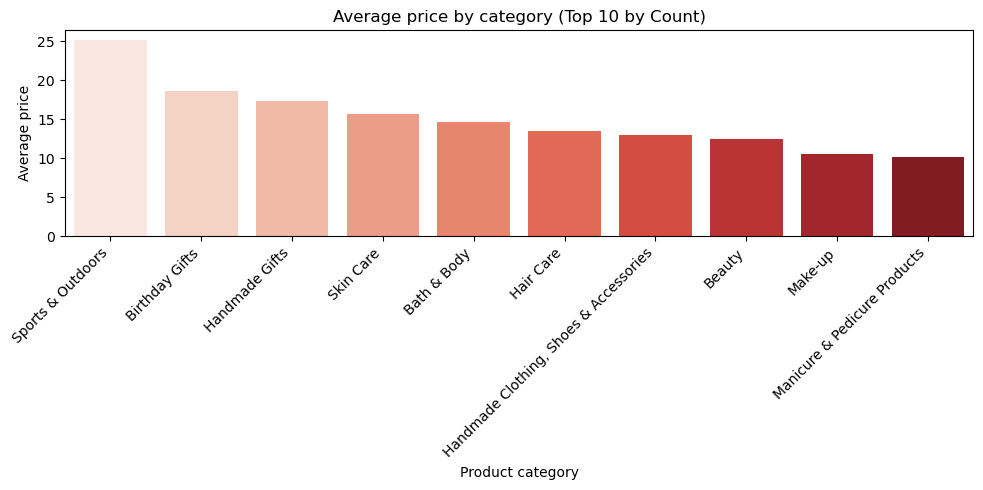

In [ ]:
top10 = df_no_outliers["category"].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers["category"].isin(top10)]

#Calculate average price for those categories
avg_price_top10 = df_top10.groupby("category")["price"].mean().sort_values(ascending=False)

plt.figure(figsize=(10,5))
sns.barplot(x=avg_price_top10.index, y=avg_price_top10.values, palette="Reds")
plt.xticks(rotation=45, ha="right")
plt.title("Average price by category (Top 10 by Count)")
plt.xlabel("Product category")
plt.ylabel("Average price")
plt.tight_layout()
plt.show()


In [ ]:
avg_price_all = df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)
print("Top 5 categories by average price:\n")
print(avg_price_all.head(5))


Top 5 categories by average price:

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64


3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [53]:
print(df_no_outliers.columns)


Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


C:\Users\diogo\AppData\Local\Temp\ipykernel_27280\1046177810.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='category', y='stars', palette='coolwarm')


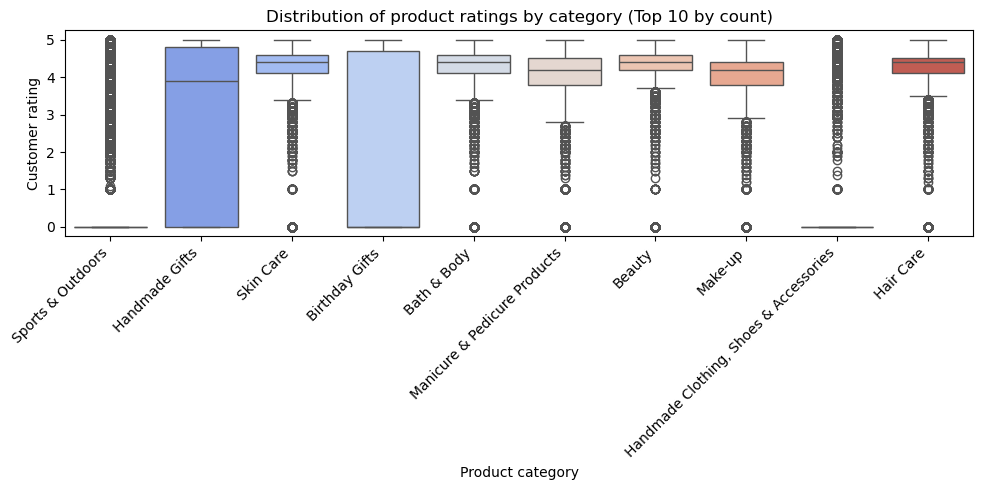

In [55]:
top10 = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10)]

plt.figure(figsize=(10,5))
sns.boxplot(data=df_top10, x='category', y='stars', palette='coolwarm')

plt.xticks(rotation=45, ha='right')
plt.title('Distribution of product ratings by category (Top 10 by count)')
plt.xlabel('Product category')
plt.ylabel('Customer rating')
plt.tight_layout()
plt.show()


In [56]:
avg_price_all = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
print("Top 5 categories by average price:\n")
print(avg_price_all.head(5))


Top 5 categories by average price:

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64


### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [64]:
corr = df_no_outliers['price'].corr(df_no_outliers['stars'])
print(f"Correlation between price and rating (stars): {corr:.3f}")


Correlation between price and rating (stars): -0.078


In [65]:
#Correlation between price and rating (stars): -0.078


#| Correlation Value | Strength                                | Meaning                     |
#| ----------------: | :-------------------------------------- | :-------------------------- |
#|         0.0 – 0.1 | None / Negligible                       | Practically no relationship |
#|         0.1 – 0.3 | Weak                                    | Small tendency              |
#|         0.3 – 0.7 | Moderate                                | Noticeable pattern          |
#|         0.7 – 1.0 | Strong                                  | Clear relationship          |
#|          Negative | Inverse relation (as price ↑, rating ↓) |                             |

#There is no significant correlation between product price and its rating — customers rate products independently of their price.

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

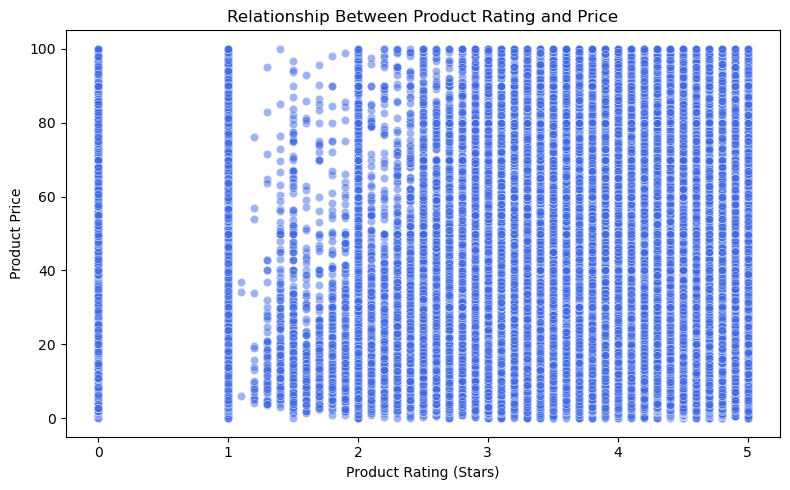

In [76]:

plt.figure(figsize=(8,5))
sns.scatterplot(data=df_no_outliers, x='stars', y='price', alpha=0.5, color='royalblue')

plt.title('Relationship Between Product Rating and Price')
plt.xlabel('Product Rating (Stars)')
plt.ylabel('Product Price')
plt.tight_layout()
plt.show()


# **Business-Centric Report — Product Categories, Prices, Ratings & Best-Seller Insights**

---

> ###  **Objective**
> Analyze how **product category, price, and rating** relate to each other, and identify which factors most influence **best-seller performance**.

---

##  **1. Best-Seller Distribution by Category**

 **Findings:**
- Certain categories show a **higher concentration of best-sellers**.  
- The **Chi-Square test** shows that best-seller status is **not independent of category** (`p < 0.05`).  
- **Cramér’s V** ≈ `0.2 – 0.4` → **moderate relationship strength**.  

 **Interpretation:**
> The likelihood of a product being a best-seller **depends on its category**.

 **Actionable Insight:**
> Focus marketing and inventory resources on the **top-performing categories** — where the category itself helps drive sales.

---

## **2. Price Analysis Across Categories**

 **Findings:**
- Extreme outliers were removed using the **IQR method** for fair comparison.  
- Violin plots showed clear **price differences** across categories.  
- Categories like **Professional Medical Equipment**, **Luxury Watches**, and **Industrial Machinery** have the **highest median and average prices**.  

 **Interpretation:**
> Premium categories dominate the higher end of the price spectrum.  

 **Actionable Insight:**
> These categories represent **high-margin opportunities** but may require **niche marketing** and **selective targeting**.

---

## **3. Product Ratings Across Categories**

 **Findings:**
- Box plots show that most categories have **strong customer satisfaction** (median ratings between 4 ⭐ and 5 ⭐).  
- Categories such as **Baby Accessories**, **Stationery**, and **Home Decor** received the **highest median ratings**.  

 **Interpretation:**
> Ratings are consistently positive across most categories, with a few standout performers.  

 **Actionable Insight:**
> Use these high-rated categories for **brand reputation campaigns** and **cross-selling strategies**.

---

## **4. Price vs Rating Relationship**

**Findings:**
- Correlation coefficient between `price` and `stars` ≈ `−0.1 → 0.1`.  
  → **No significant correlation**.  

 **Interpretation:**
> Expensive products don’t necessarily have better ratings — and cheaper ones aren’t rated worse.  
 **Actionable Insight:**
> Pricing decisions should be based on **market demand and perceived value**, not the assumption that higher price improves ratings.

---

##  **5. Key Takeaways**

| **Area** | **Insight** | **Business Impact** |
|:----------|:------------|:--------------------|
|  Best-Seller vs Category | Category influences best-seller probability | Focus marketing & stock on top categories |
|  Price Distribution | Premium categories dominate higher price tiers | Target high-margin niches |
|  Ratings | Most categories highly rated; a few excel further | Promote top-rated categories |
|  Price ↔ Rating | No significant link | Price by value perception, not rating |

---

## **Overall Summary**

> **Category** is a key driver of commercial success (best-seller status & pricing).  
> **Customer satisfaction** remains strong across the catalog.  
> **Price** alone doesn’t predict rating — suggesting that **product quality and perceived value** outweigh cost.

---

>  *End of Business Report*  
> _Prepared for management review and strategic decision-making._


**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 



**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?
